# Guitar tab transcription: audio → string & fret

**Goal.** Given a recording of solo acoustic guitar, predict **which string and which fret** is
sounding at every moment, and render it as guitar tablature.

**Why it matters.** Sheet music only gives pitch, but guitarists read *tabs*: the same note can be
played in up to 5 places on the neck, and the tab tells you which one. Writing tabs by ear is slow
and needs a trained ear; an automatic transcriber helps learners, teachers and anyone who wants to
write down what they just played.

**How the model is used.** A web service accepts an audio file and returns ASCII tab + JSON notes.

**ML framing.** The audio is cut into frames of ~23 ms. For every frame and each of the 6 strings we
predict one of 21 classes: *not playing*, *open*, or *fret 1–19*. That is **6 multiclass
classification problems** on the same features (a log-scaled Constant-Q spectrogram).

**Data.** [GuitarSet](https://zenodo.org/records/3371780) (CC-BY-4.0): 360 recordings, 6 guitarists,
5 styles, strummed (*comp*) and soloed versions, with every note labelled with its string and fret.
Run `data/get_data.py` to recreate the files used below.

This notebook follows the course structure (CRISP-DM): data preparation → validation framework → EDA
→ feature importance → models → final model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

import sys
sys.path.insert(0, "../production")  # shared project code: production/guitar.py
import guitar as F

# --- Plot style: recessive axes/grid, fixed categorical order (one colour per string) ---
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
STRING_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # E A D G B e
PAIR = STRING_COLORS[:2]  # two-series charts (e.g. comp vs solo)
BLUES = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
BLUE_RED = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#ec8f8e", "#c43b3b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": cycler(color=STRING_COLORS), "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})
BAR = dict(edgecolor=SURFACE, linewidth=2)  # 2px surface gap between adjacent bars

STRINGS = F.STRING_NAMES  # ['E', 'A', 'D', 'G', 'B', 'e'], low to high
FREQS = F.cqt_bin_frequencies()
OCTAVE_TICKS = np.arange(0, F.N_BINS, F.BINS_PER_OCTAVE)
OCTAVE_LABELS = [f"E{2 + i}" for i in range(len(OCTAVE_TICKS))]

## 1. Data preparation

`data/get_data.py` already converted the raw dataset into three files:

* `tracks.csv`: one row per recording (player, style, tempo, key, comp/solo)
* `notes.csv`: one row per annotated note (string, fret, pitch, start, duration)
* `frames.npz`: the frame-level table. `X` holds 168 spectrogram values (dB) per frame, `y` holds the
  class of each string (0 = not playing, 1 = open, 2..20 = frets 1..19)

In [2]:
tracks = pd.read_csv("../data/processed/tracks.csv", index_col="track_id")
notes = pd.read_csv("../data/processed/notes.csv")
data = np.load("../data/processed/frames.npz")
X = data["X"].astype(np.float32)
y = data["y"]
track = data["track"]
frame_time = data["time"]

print(f"recordings: {len(tracks)}   notes: {len(notes)}   frames: {len(X)}   features per frame: {X.shape[1]}")
tracks.head()

recordings: 360   notes: 62476   frames: 472560   features per frame: 168


,name,player,style,progression,tempo,key,mode,duration,n_frames,n_notes
track_id,,,,,,,,,,
0,00_BN1-129-Eb_comp,0,Bossa Nova,1,129,Eb,comp,22.324399,962,133
1,00_BN1-129-Eb_solo,0,Bossa Nova,1,129,Eb,solo,22.324399,962,71
2,00_BN1-147-Gb_comp,0,Bossa Nova,1,147,Gb,comp,19.585624,844,151
3,00_BN1-147-Gb_solo,0,Bossa Nova,1,147,Gb,solo,19.585624,844,89
4,00_BN2-131-B_comp,0,Bossa Nova,2,131,B,comp,29.306395,1263,239


In [3]:
notes.head()

,track_id,name,string,midi,fret,start,duration
0,0,00_BN1-129-Eb_comp,0,44.018917,4,7.457274,0.464399
1,0,00_BN1-129-Eb_comp,0,44.224918,4,7.923578,0.922993
2,0,00_BN1-129-Eb_comp,0,44.106065,4,8.870789,0.191565
3,0,00_BN1-129-Eb_comp,0,46.053185,6,14.834689,0.487619
4,0,00_BN1-129-Eb_comp,0,46.071249,6,15.333215,1.416417


### Data quality checks
The dataset is audio + annotations, so "missing values" means missing files, broken frames or
impossible labels. We check each.

In [4]:
checks = {
    "recordings without notes": int((tracks["n_notes"] == 0).sum()),
    "NaN / inf in X": int((~np.isfinite(X)).sum()),
    "X min (dB)": float(X.min()),
    "X max (dB)": float(X.max()),
    "frets outside 0..19": int(((notes["fret"] < 0) | (notes["fret"] > F.MAX_FRET)).sum()),
    "notes with duration <= 0": int((notes["duration"] <= 0).sum()),
    "label classes present": f"{y.min()}..{y.max()}",
    "frames per recording (min / max)": f"{tracks['n_frames'].min()} / {tracks['n_frames'].max()}",
    "total audio (hours)": round(tracks["duration"].sum() / 3600, 2),
}
pd.Series(checks, name="value").to_frame()

,value
recordings without notes,0
NaN / inf in X,0
X min (dB),-80.0
X max (dB),0.0
frets outside 0..19,0
notes with duration <= 0,0
label classes present,0..20
frames per recording (min / max),621 / 1969
total audio (hours),3.05


Nothing is missing or broken. The only thing that looks like a "missing value" is the spectrogram
floor: values are clipped at −80 dB below the loudest point of each clip, so silence shows up as
exactly −80 (see the distribution below).

The annotated pitch is a continuous MIDI value (players bend notes slightly). We round it to the
nearest semitone to get the fret; the deviation is small:

In [5]:
deviation = notes["midi"] - notes["midi"].round()
deviation.describe(percentiles=[0.01, 0.5, 0.99]).round(3).to_frame("pitch − nearest semitone")

,pitch − nearest semitone
count,62476.000
mean,0.071
std,0.110
min,-0.500
1%,-0.360
50%,0.076
99%,0.359
max,0.500


## 2. Validation framework

Neighbouring frames are almost identical (a note lasts ~10 frames), so a **random** split of frames
would leak: the model would be tested on near-copies of training frames. All 6 guitarists also play
the same set of chord progressions.

In real use the service always hears a **guitarist it has never heard**, so we split by guitarist:

* **train**: 4 guitarists
* **validation**: 1 guitarist (model selection and tuning)
* **test**: 1 guitarist (touched once, at the very end)

This is the course's train/validation/test split (≈ 67 / 17 / 17%), with the guitarist as the unit.
The choice of who goes where is random but fixed with a seed, before looking at any results.

In [6]:
rng = np.random.default_rng(1)
test_player, val_player = rng.permutation(6)[:2]

def split_of(player):
    if player == test_player:
        return "test"
    if player == val_player:
        return "val"
    return "train"

tracks["split"] = tracks["player"].map(split_of)
frame_split = tracks["split"].to_numpy()[track]
notes = notes.merge(tracks[["player", "style", "mode", "split"]], left_on="track_id", right_index=True)

print("test guitarist:", test_player, "  validation guitarist:", val_player)
pd.DataFrame({
    "recordings": tracks.groupby("split").size(),
    "frames": pd.Series(frame_split).value_counts(),
    "share of frames": pd.Series(frame_split).value_counts(normalize=True).round(3),
}).loc[["train", "val", "test"]]

test guitarist: 4   validation guitarist: 0


,recordings,frames,share of frames
train,240,315040,0.667
val,60,78760,0.167
test,60,78760,0.167


As in the course, the EDA below uses the **full training data** (train + validation guitarists)
and never looks at the test guitarist.

In [7]:
full_train = frame_split != "test"
X_ft, y_ft = X[full_train], y[full_train]
notes_ft = notes[notes["split"] != "test"]
tracks_ft = tracks[tracks["split"] != "test"]
print("full train frames:", len(X_ft), "  notes:", len(notes_ft), "  recordings:", len(tracks_ft))

full train frames: 393800   notes: 52223   recordings: 300


## 3. Exploratory data analysis

### 3.1 Recordings
The dataset is perfectly balanced by design: every guitarist plays the same 30 excerpts
(5 styles × 3 progressions × 2 tempos), each once strummed (*comp*) and once as a solo.

In [8]:
overview = tracks_ft.groupby(["style", "mode"]).agg(
    recordings=("name", "size"),
    minutes=("duration", lambda d: round(d.sum() / 60, 1)),
    notes=("n_notes", "sum"),
    tempo_min=("tempo", "min"),
    tempo_max=("tempo", "max"),
)
overview["notes per second"] = (overview["notes"] / (overview["minutes"] * 60)).round(2)
overview

recordings  minutes  notes  tempo_min  tempo_max  \
style             mode                                                     
Bossa Nova        comp          30     12.6   5608        119        166   
                  solo          30     12.6   2211        119        166   
Funk              comp          30     16.4   8368         97        119   
                  solo          30     16.4   3196         97        119   
Jazz              comp          30     12.1   5440        110        200   
                  solo          30     12.1   2379        110        200   
Rock              comp          30     15.4  10529         85        148   
                  solo          30     15.4   3064         85        148   
Singer-Songwriter comp          30     19.6   8001         68        107   
                  solo          30     19.6   3427         68        107   

                        notes per second  
style             mode                    
Bossa Nova        comp              7.42  
                  solo              2.92  
Funk              comp              8.50  
                  solo              3.25  
Jazz              comp              7.49  
                  solo              3.28  
Rock              comp             11.40  
                  solo              3.32  
Singer-Songwriter comp              6.80  
                  solo              2.91

Strummed accompaniment (*comp*) has 2–3.5× more notes per second than the solos, because every strum
hits several strings at once. Rock comping is the densest (11 notes/s).

### 3.2 Notes: which strings and frets are used?
The fretboard heatmap counts how often each (string, fret) position is played. It is the
distribution of our target variable.

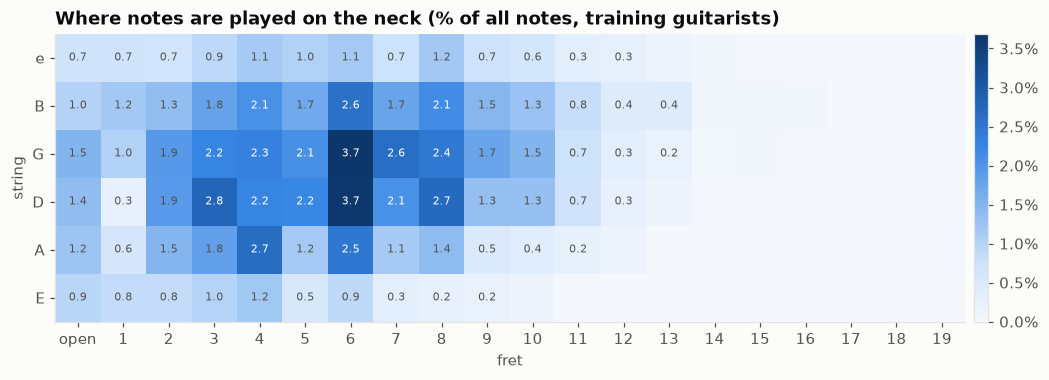

In [9]:
fretboard = pd.crosstab(notes_ft["string"], notes_ft["fret"]).reindex(
    index=range(6), columns=range(F.MAX_FRET + 1), fill_value=0)

fig, ax = plt.subplots(figsize=(11, 3.4))
share = fretboard / fretboard.to_numpy().sum()
im = ax.imshow(share.iloc[::-1], cmap=BLUES, aspect="auto")
ax.set_yticks(range(6), [STRINGS[s] for s in range(5, -1, -1)])
ax.set_xticks(range(F.MAX_FRET + 1), ["open"] + [str(f) for f in range(1, F.MAX_FRET + 1)])
ax.set_xlabel("fret")
ax.set_ylabel("string")
ax.grid(False)
for (r, c), v in np.ndenumerate(share.iloc[::-1].to_numpy()):
    if v >= 0.002:
        ax.text(c, r, f"{100 * v:.1f}", ha="center", va="center", fontsize=7,
                color="white" if v > share.to_numpy().max() * 0.55 else INK_2)
ax.set_title("Where notes are played on the neck (% of all notes, training guitarists)")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, format=lambda v, _: f"{100 * v:.1f}%")
plt.show()

In [10]:
fret_summary = notes_ft.groupby("string")["fret"].agg(
    notes="size", median_fret="median", max_fret="max",
    share_above_12=lambda f: round((f > 12).mean() * 100, 2))
fret_summary.index = STRINGS
fret_summary

,notes,median_fret,max_fret,share_above_12
E,3719,3.0,14,0.03
A,7913,4.0,13,0.01
D,11958,6.0,19,0.75
G,12786,6.0,18,1.31
B,10494,6.0,19,3.24
e,5353,6.0,17,2.47


* Almost all playing happens in the **first 12 frets**; frets above 14 are extremely rare (a handful
  of notes). Those classes will be very hard to learn, which matters for metrics (§3.4).
* The middle strings (D, G, B) carry the most notes; the low E and high e strings are used least.

### 3.3 Note durations and polyphony

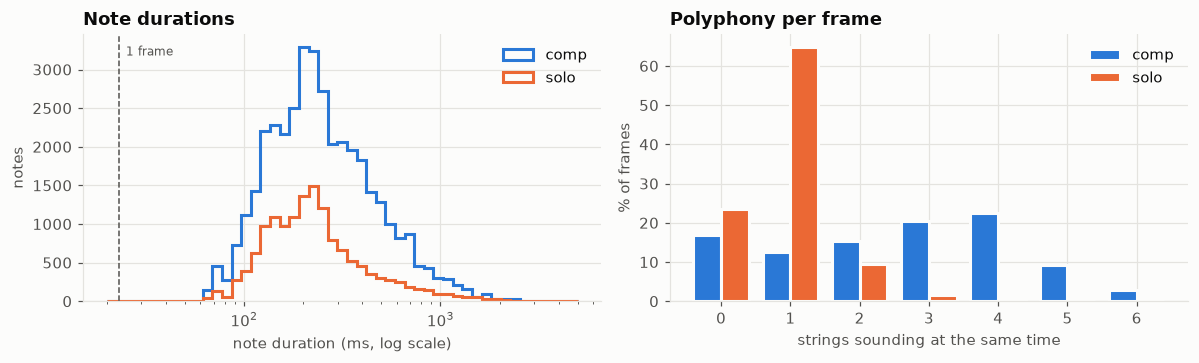

median note duration: 226 ms  = 9.8 frames
notes shorter than 3 frames: 0.4 %


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

ax = axes[0]
durations_ms = notes_ft["duration"] * 1000
bins = np.logspace(np.log10(20), np.log10(5000), 50)
for mode, color in zip(["comp", "solo"], PAIR):
    ax.hist(durations_ms[notes_ft["mode"] == mode], bins=bins, color=color, histtype="step",
            linewidth=2, label=mode)
ax.axvline(F.frame_seconds() * 1000, color=INK_2, linewidth=1, linestyle="--")
ax.text(F.frame_seconds() * 1000 * 1.08, ax.get_ylim()[1] * 0.92, "1 frame", color=INK_2, fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("note duration (ms, log scale)")
ax.set_ylabel("notes")
ax.set_title("Note durations")
ax.legend()

ax = axes[1]
n_sounding = (y_ft > 0).sum(axis=1)
mode_of_frame = tracks["mode"].to_numpy()[track][full_train]
width = 0.4
for i, (mode, color) in enumerate(zip(["comp", "solo"], PAIR)):
    counts = np.bincount(n_sounding[mode_of_frame == mode], minlength=7)
    ax.bar(np.arange(7) + (i - 0.5) * width, 100 * counts / counts.sum(), width=width,
           color=color, label=mode, **BAR)
ax.set_xticks(range(7))
ax.set_xlabel("strings sounding at the same time")
ax.set_ylabel("% of frames")
ax.set_title("Polyphony per frame")
ax.legend()
plt.tight_layout()
plt.show()

print("median note duration:", round(durations_ms.median()), "ms  =",
      round(durations_ms.median() / (F.frame_seconds() * 1000), 1), "frames")
print("notes shorter than 3 frames:", round((durations_ms < 3 * F.frame_seconds() * 1000).mean() * 100, 1), "%")

* A typical note lasts ~0.2 s ≈ 10 frames, so each note produces several training rows that are
  near-duplicates. This is why the split has to be by guitarist.
* Solos are mostly **one string at a time**; strummed parts are mostly **chords of 4–6 strings**.
  A frame with nothing playing is common in both (pauses, gaps between strums).

### 3.4 The target variable and the dummy model
For each string, most frames are "not playing". A **dummy model** that always predicts
"not playing" therefore has a high accuracy without being useful at all (course lesson 4.2).

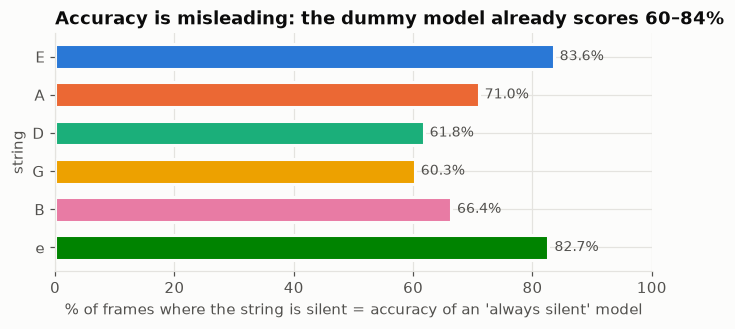

frames with no string playing at all: 20.3 %


In [12]:
silent_share = (y_ft == 0).mean(axis=0)

fig, ax = plt.subplots(figsize=(7, 2.8))
bars = ax.barh(STRINGS[::-1], 100 * silent_share[::-1], color=STRING_COLORS[::-1], height=0.65, **BAR)
for bar, v in zip(bars, silent_share[::-1]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f"{100 * v:.1f}%",
            va="center", color=INK_2, fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("% of frames where the string is silent = accuracy of an 'always silent' model")
ax.set_ylabel("string")
ax.set_title("Accuracy is misleading: the dummy model already scores 60–84%")
plt.show()

print("frames with no string playing at all:", round((y_ft == 0).all(axis=1).mean() * 100, 1), "%")

In [13]:
class_counts = pd.DataFrame(
    {STRINGS[s]: np.bincount(y_ft[:, s], minlength=F.N_CLASSES) for s in range(6)},
    index=["silent", "open"] + [f"fret {f}" for f in range(1, F.MAX_FRET + 1)])
class_counts.T

,silent,open,fret 1,fret 2,fret 3,fret 4,fret 5,fret 6,fret 7,fret 8,...,fret 10,fret 11,fret 12,fret 13,fret 14,fret 15,fret 16,fret 17,fret 18,fret 19
E,329032,11494,8375,6916,9258,9810,4056,8140,2489,1917,...,911,105,85,0,15,0,0,0,0,0
A,279553,7953,4784,13153,15914,20544,8570,19135,7331,9695,...,1785,1276,947,7,0,0,0,0,0,0
D,243254,9667,1763,15202,20508,14081,13830,22928,12071,18557,...,7640,3963,1855,639,64,23,8,7,19,21
G,237391,9890,8483,13071,15297,13733,13650,23950,15845,15422,...,8994,4377,2040,1220,151,611,18,35,24,0
B,261317,8683,9474,10356,12500,12585,10551,17838,10140,13521,...,7526,4928,2237,2300,491,355,190,29,0,14
e,325600,7726,5119,4764,6152,6672,6255,8263,4049,6449,...,3985,1677,1579,1072,288,97,145,11,0,0


Two consequences for modelling:

* **Accuracy is the wrong metric.** We will use precision / recall / F1 on the *notes* (a frame-string
  counts only when the right fret is predicted on the right string), as in course module 4.
* **Strong class imbalance.** Rare classes (high frets) have only tens of frames per string. We will
  try class weights in the models.

### 3.5 Pitch vs string: how ambiguous is the tab?
The core difficulty: one pitch can be played on several strings. For every pitch in the training
data, how are its notes spread over the strings?

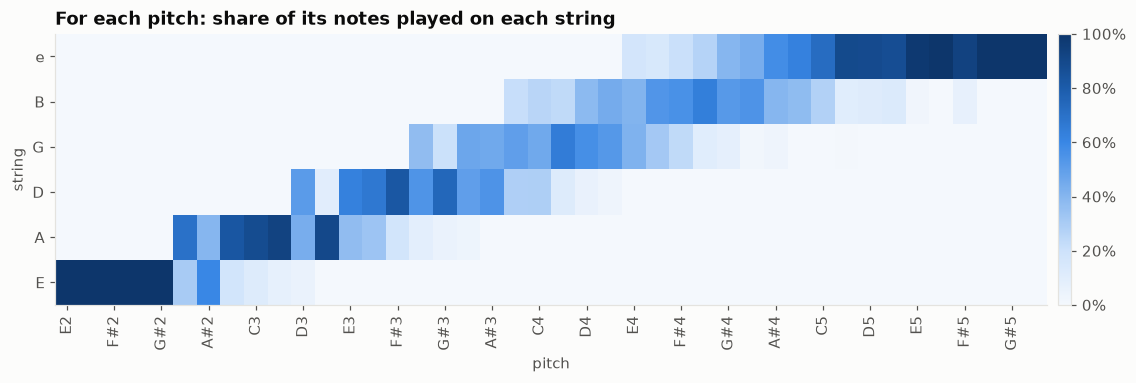

In [14]:
notes_ft = notes_ft.assign(pitch=notes_ft["midi"].round().astype(int))
pitch_string = pd.crosstab(notes_ft["pitch"], notes_ft["string"]).reindex(columns=range(6), fill_value=0)
all_pitches = range(pitch_string.index.min(), pitch_string.index.max() + 1)
pitch_share = (pitch_string.reindex(all_pitches, fill_value=0)
               .pipe(lambda t: t.div(t.sum(axis=1).replace(0, 1), axis=0)))

note_names = [f"{n}" for n in pd.Index(pitch_share.index).map(
    lambda m: ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"][m % 12] + str(m // 12 - 1))]

fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(pitch_share.T.iloc[::-1], cmap=BLUES, aspect="auto", vmin=0, vmax=1)
ax.set_yticks(range(6), STRINGS[::-1])
ax.set_xticks(range(len(note_names))[::2], note_names[::2], rotation=90)
ax.set_xlabel("pitch")
ax.set_ylabel("string")
ax.grid(False)
ax.set_title("For each pitch: share of its notes played on each string")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, format=lambda v, _: f"{100 * v:.0f}%")
plt.show()

In [15]:
top_share = pitch_string.max(axis=1) / pitch_string.sum(axis=1)
strings_used = (pitch_string > 0).sum(axis=1)
majority_acc = pitch_string.max(axis=1).sum() / pitch_string.to_numpy().sum()

print(f"pitches in the data: {len(pitch_string)}")
print(f"pitches played on more than one string: {(strings_used > 1).sum()}")
print(f"notes whose pitch is played on more than one string: "
      f"{pitch_string[strings_used > 1].to_numpy().sum() / pitch_string.to_numpy().sum():.1%}")
print(f"'most common string for this pitch' rule gets the string right for {majority_acc:.1%} of notes")

pitches in the data: 42
pitches played on more than one string: 33
notes whose pitch is played on more than one string: 95.0%
'most common string for this pitch' rule gets the string right for 63.5% of notes


* Each pitch spreads over a diagonal band of 2–4 strings: the tab really is ambiguous.
* Even a perfect pitch detector plus the best "pick the most common string for this pitch" rule gets
  the string wrong for a sizeable share of notes (number above). To do better, a model has to hear
  the *timbre* of the string (thick wound strings sound duller) or use context. This is the baseline
  the string-choice part of our models has to beat.

### 3.6 The features: what does the spectrogram look like?

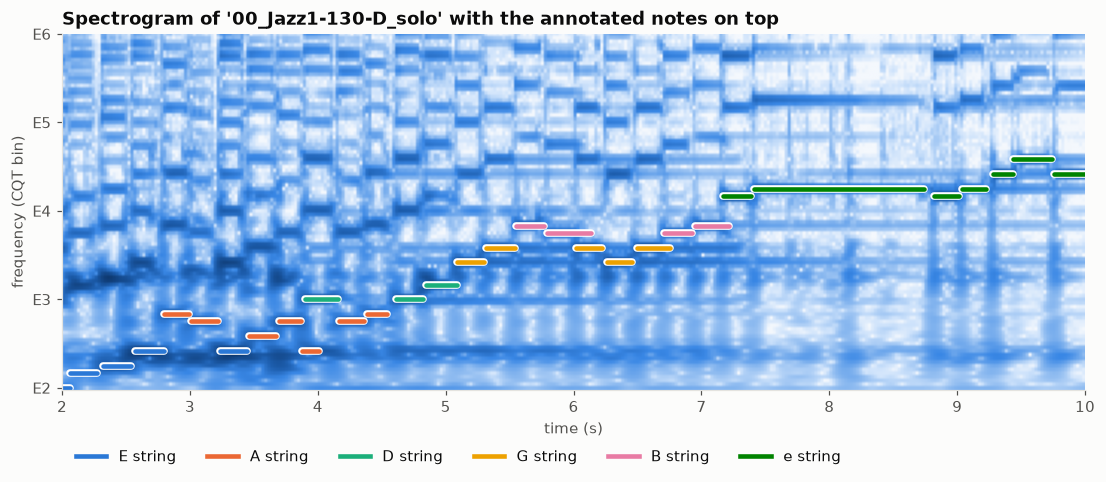

In [16]:
example = tracks_ft[(tracks_ft["mode"] == "solo") & (tracks_ft["style"] == "Jazz")].index[0]
t0, t1 = 2.0, 10.0
rows = (track == example) & (frame_time >= t0) & (frame_time < t1)
ex_notes = notes[(notes["track_id"] == example) & (notes["start"] < t1) & (notes["start"] + notes["duration"] > t0)]

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.imshow(X[rows].T, origin="lower", aspect="auto", cmap=BLUES,
          extent=[t0, t1, -0.5, F.N_BINS - 0.5], vmin=-80, vmax=0)
ax.grid(False)
for note in ex_notes.itertuples():
    b = (round(note.midi) - 40) * 2  # bin of the fundamental (2 bins per semitone from E2)
    ax.plot([max(note.start, t0), min(note.start + note.duration, t1)], [b, b],
            color=STRING_COLORS[note.string], linewidth=3, solid_capstyle="round",
            path_effects=[pe.Stroke(linewidth=5, foreground="white"), pe.Normal()])
for s in range(6):
    ax.plot([], [], color=STRING_COLORS[s], linewidth=3, label=f"{STRINGS[s]} string")
ax.set_yticks(OCTAVE_TICKS, OCTAVE_LABELS)
ax.set_ylim(-0.5, 96)  # up to E6: where the fundamentals are
ax.set_xlabel("time (s)")
ax.set_ylabel("frequency (CQT bin)")
ax.set_title(f"Spectrogram of '{tracks.loc[example, 'name']}' with the annotated notes on top")
ax.legend(ncol=6, loc="upper left", bbox_to_anchor=(0, -0.13))
plt.show()

Each annotated note (coloured line, at its fundamental frequency) sits on a dark horizontal streak in
the spectrogram: the labels line up with the audio. Above each fundamental you can see fainter
copies at 2×, 3×, 4× the frequency (harmonics). How strong each harmonic is depends on the string,
which is exactly the "timbre" information a model can use to pick the string.

Value distribution of the features, and the average spectrum when each string is or isn't playing:

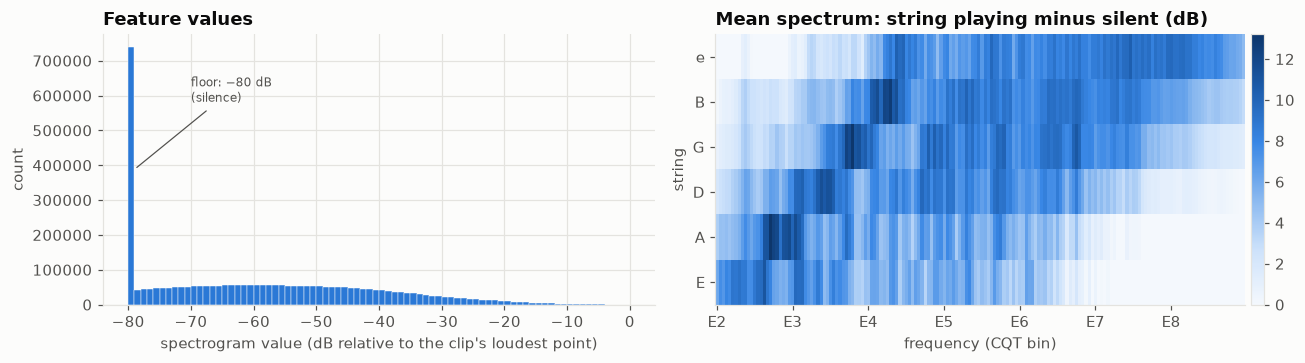

share of values at the -80 dB floor: 21.1%


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))

ax = axes[0]
sample = X_ft[::20].ravel()
ax.hist(sample, bins=80, color=STRING_COLORS[0], edgecolor=SURFACE, linewidth=0.3)
ax.set_xlabel("spectrogram value (dB relative to the clip's loudest point)")
ax.set_ylabel("count")
ax.set_title("Feature values")
ax.annotate("floor: −80 dB\n(silence)", xy=(-79, ax.get_ylim()[1] * 0.5), xytext=(-70, ax.get_ylim()[1] * 0.75),
            color=INK_2, fontsize=8, arrowprops=dict(arrowstyle="-", color=INK_2, lw=0.8))

ax = axes[1]
diff = np.stack([X_ft[y_ft[:, s] > 0].mean(axis=0) - X_ft[y_ft[:, s] == 0].mean(axis=0)
                 for s in range(6)])
im = ax.imshow(diff[::-1], cmap=BLUES, vmin=0, aspect="auto")
ax.set_yticks(range(6), STRINGS[::-1])
ax.set_xticks(OCTAVE_TICKS, OCTAVE_LABELS)
ax.grid(False)
ax.set_xlabel("frequency (CQT bin)")
ax.set_ylabel("string")
ax.set_title("Mean spectrum: string playing minus silent (dB)")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01)
plt.tight_layout()
plt.show()

print(f"share of values at the -80 dB floor: {(X_ft <= -79.99).mean():.1%}")

* Values span −80…0 dB; about a fifth of all values sit on the −80 dB floor (very quiet bins,
  mostly at the highest frequencies). The dB (log) scale is what makes the distribution usable,
  just like the log transform of prices in course module 2.
* When a string plays, energy rises most around that string's own frequency range, and the hot
  region moves up from the low E string to the high e string. The high strings also add energy far
  above their range (bright harmonics). The features clearly carry signal about *which* string is
  playing.

### 3.7 Differences between guitarists
Since we test on an unseen guitarist, how different are the players?

In [18]:
player_stats = notes_ft.groupby("player").agg(
    notes=("fret", "size"),
    median_fret=("fret", "median"),
    share_above_fret_7=("fret", lambda f: round((f > 7).mean() * 100, 1)),
    median_duration_ms=("duration", lambda d: round(d.median() * 1000)),
)
player_frames = pd.DataFrame({"player": tracks["player"].to_numpy()[track][full_train],
                              "sounding": (y_ft > 0).sum(axis=1)})
player_stats["mean strings sounding"] = player_frames.groupby("player")["sounding"].mean().round(2)
player_stats["split"] = player_stats.index.map(split_of)
player_stats

,notes,median_fret,share_above_fret_7,median_duration_ms,mean strings sounding,split
player,,,,,,
0,13223,6.0,29.9,232,2.37,val
1,11268,6.0,35.9,186,1.60,train
2,9659,4.0,16.5,255,1.69,train
3,9358,5.0,20.6,232,1.56,train
5,8715,6.0,28.3,226,1.50,train


The guitarists play the same material but differently: how high up the neck they go (17–36% of notes
above fret 7) and how long they let notes ring differ noticeably. The **validation guitarist (0)
plays the most notes and far more chords** (2.4 strings at a time vs 1.5–1.7 for the others), so
the validation set is harder than average for the polyphonic parts. Worth keeping in mind when
comparing validation and test scores.

## 4. Feature importance

### 4.1 Mutual information
Mutual information (course lesson 3.6) measures how much knowing a feature tells us about the
target. We compute it between every spectrogram bin and each string's class (21 values), on a random
sample of 20,000 training frames.

In [19]:
from sklearn.feature_selection import mutual_info_classif

idx = np.random.default_rng(1).choice(len(X_ft), size=20_000, replace=False)
X_s, y_s = X_ft[idx], y_ft[idx]

mi = np.stack([
    mutual_info_classif(X_s, y_s[:, s], discrete_features=False, random_state=1, n_jobs=-1)
    for s in range(6)
])
mi_df = pd.DataFrame(mi.T, columns=STRINGS)
mi_df.index = [f"{f:.0f} Hz" for f in FREQS]

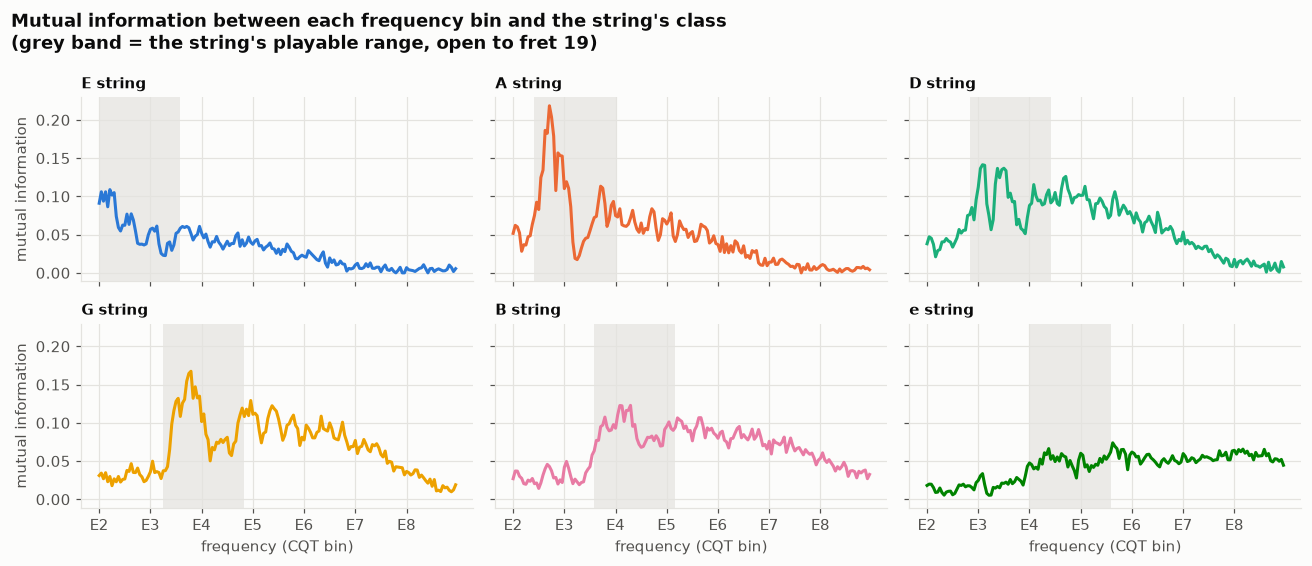

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.2), sharex=True, sharey=True)
for s, ax in enumerate(axes.ravel()):
    lo, hi = (F.OPEN_STRING_MIDI[s] - 40) * 2, (F.OPEN_STRING_MIDI[s] + F.MAX_FRET - 40) * 2
    ax.axvspan(lo, hi, color=GRID, alpha=0.7, linewidth=0)
    ax.plot(np.arange(F.N_BINS), mi[s], color=STRING_COLORS[s])
    ax.set_title(f"{STRINGS[s]} string", fontsize=10)
    ax.set_xticks(OCTAVE_TICKS, OCTAVE_LABELS)
for ax in axes[:, 0]:
    ax.set_ylabel("mutual information")
for ax in axes[1]:
    ax.set_xlabel("frequency (CQT bin)")
fig.suptitle("Mutual information between each frequency bin and the string's class\n"
             "(grey band = the string's playable range, open to fret 19)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

In [21]:
top_bins = pd.DataFrame({s: mi_df[s].sort_values(ascending=False).index[:5] for s in STRINGS})
top_bins.index = [f"#{i + 1}" for i in range(5)]
top_bins

,E,A,D,G,B,e
#1,95 Hz,135 Hz,175 Hz,285 Hz,403 Hz,1017 Hz
#2,85 Hz,139 Hz,180 Hz,277 Hz,349 Hz,1047 Hz
#3,90 Hz,127 Hz,233 Hz,269 Hz,359 Hz,427 Hz
#4,101 Hz,131 Hz,214 Hz,302 Hz,392 Hz,1077 Hz
#5,98 Hz,143 Hz,170 Hz,320 Hz,381 Hz,5920 Hz


* For the E, A, D and G strings the highest peak lies inside the string's playable range (the
  fundamentals), and the peaks move up the spectrum from string to string.
* For the B and e strings the information is spread out: there is about as much **above** their range
  (harmonics) as inside it. The lowest bins only matter for the low strings.
* No bin is useless across all strings, so we keep all 168 features.

### 4.2 Correlation
Correlation (course lesson 3.7) between each bin and "is this string playing?", and between the bins
themselves.

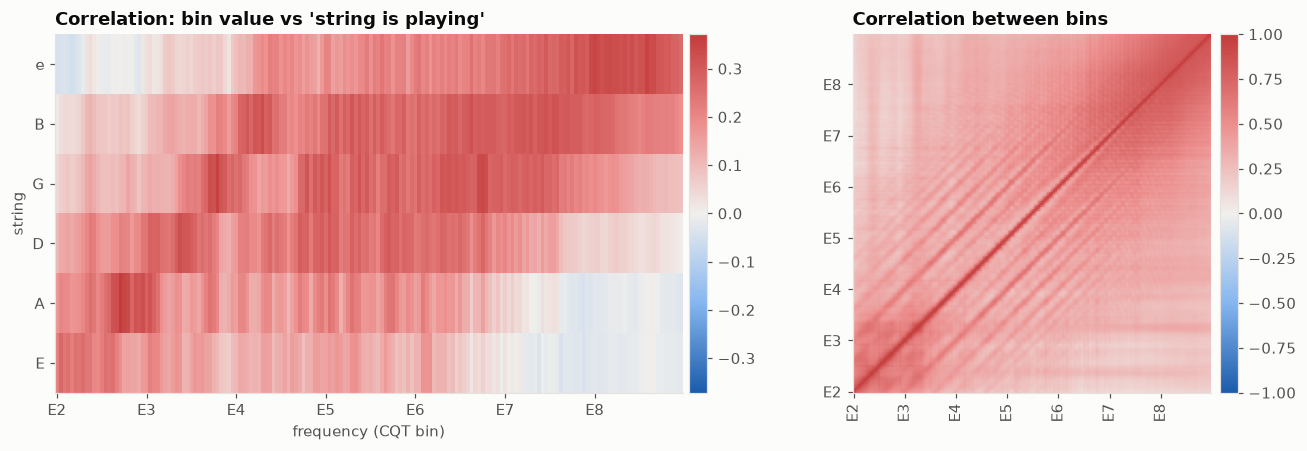

mean correlation with the neighbouring bin: 0.85   with the bin one octave up: 0.63


In [22]:
active = (y_s > 0).astype(np.float32)
Xc = (X_s - X_s.mean(axis=0)) / X_s.std(axis=0)
Ac = (active - active.mean(axis=0)) / active.std(axis=0)
corr_target = (Ac.T @ Xc) / len(Xc)           # (6 strings, 168 bins)
corr_bins = np.corrcoef(X_s, rowvar=False)    # (168, 168)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
lim = np.abs(corr_target).max()
im = ax.imshow(corr_target[::-1], cmap=BLUE_RED, vmin=-lim, vmax=lim, aspect="auto")
ax.set_yticks(range(6), STRINGS[::-1])
ax.set_xticks(OCTAVE_TICKS, OCTAVE_LABELS)
ax.set_xlabel("frequency (CQT bin)")
ax.set_ylabel("string")
ax.grid(False)
ax.set_title("Correlation: bin value vs 'string is playing'")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01)

ax = axes[1]
im = ax.imshow(corr_bins, cmap=BLUE_RED, vmin=-1, vmax=1, origin="lower")
ax.set_xticks(OCTAVE_TICKS, OCTAVE_LABELS, rotation=90)
ax.set_yticks(OCTAVE_TICKS, OCTAVE_LABELS)
ax.grid(False)
ax.set_title("Correlation between bins")
fig.colorbar(im, ax=ax, fraction=0.045, pad=0.02)
plt.tight_layout()
plt.show()

near = np.mean([corr_bins[i, i + 1] for i in range(F.N_BINS - 1)])
octave = np.mean([corr_bins[i, i + 24] for i in range(F.N_BINS - 24)])
print(f"mean correlation with the neighbouring bin: {near:.2f}   with the bin one octave up: {octave:.2f}")

* Almost every bin correlates **positively** with every string playing: when anything plays, the
  whole spectrum gets louder, and strings tend to play together (chords). The strongest correlations
  still follow each string's own region, and for the low strings the correlation fades to zero
  above ~E7.
* The features are strongly correlated with their neighbours and with bins an octave apart
  (harmonics). Correlated features are fine for tree models; for logistic regression they are a
  reason to use regularisation (the `C` parameter), as in course module 2.13.

### EDA summary

* **Data**: 360 recordings, 3 h of audio, 62k notes, no missing or broken values. Split by guitarist:
  4 train / 1 validation (player 0) / 1 test (player 4).
* **Target**: 6 strings × 21 classes. Each string is silent in 60–84% of frames, so accuracy is
  misleading (the dummy model scores 60–84%); we will use precision / recall / F1 on notes.
  Frets above 12 are rare (≤ 3% of notes on any string): strong class imbalance.
* **Ambiguity**: 95% of notes have a pitch that is played on more than one string. Picking the most
  common string for a pitch gets only 63.5% of strings right; that is the bar for the string choice.
* **Features**: 168 log-scaled spectrogram bins. Informative bins follow each string's range, plus
  harmonics for the high strings. Neighbouring bins are strongly correlated (0.85), which calls for
  regularisation in linear models.
* **Guitarists differ** in neck position, note length and how many strings they play together, so a
  per-guitarist split is necessary and the validation guitarist (the most chordal) is a tough test.

## 5. Baseline models

### 5.1 How we measure
Every frame has 6 string cells. A cell where the string is playing is a **note**. Following course
module 4 (precision and recall), we count:

* **tab precision**: of the notes the model predicted, the share with the right string *and* fret
* **tab recall**: of the real notes, the share the model found with the right string and fret
* **tab F1**: the harmonic mean of the two, our **main metric**
* **pitch precision / recall / F1**: the same, but a note counts if its *pitch* is right, whatever
  string it was put on. This is what a pitch detector would be scored on.
* **string choice**: of the notes with the right pitch, the share also on the right string.
  EDA §3.5 gives the bar for this one: 63.5% with the "most common string" rule.

The code lives in `production/guitar.py` so `production/train.py` can use exactly the same metrics.

In [23]:
import time
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from guitar import tab_metrics, decide, StringwiseClassifier

train_mask = frame_split == "train"
val_mask = frame_split == "val"
y_train_all, y_val = y[train_mask], y[val_mask]

results = []  # one row per model we try, shown at the end of every section

def evaluate(name, y_pred, **extra):
    row = {"model": name, **tab_metrics(y_val, y_pred), **extra}
    results.append(row)
    return row

def show(rows):
    cols = ["model", "tab_f1", "tab_precision", "tab_recall", "pitch_f1", "string_choice", "accuracy"]
    extra = [c for c in pd.DataFrame(rows).columns if c not in cols]
    return pd.DataFrame(rows)[cols + extra].round(3)

### 5.2 Dummy model
Always predict "not playing" (course lesson 4.2):

In [24]:
evaluate("dummy: always silent", np.zeros_like(y_val))
show(results)

,model,tab_f1,tab_precision,tab_recall,pitch_f1,string_choice,accuracy,pitch_precision,pitch_recall
0,dummy: always silent,0.0,0.0,0.0,0.0,0.0,0.606,0.0,0.0


61% accuracy, and an F1 of 0: the dummy finds no notes at all. From now on accuracy is shown only to
make that point; we select models by **tab F1**.

### 5.3 Logistic regression

One multinomial logistic regression per string (21 classes each), wrapped in `StringwiseClassifier`
from `production/guitar.py` so the 6 models train in parallel and behave like one. Features are standardised
first: logistic regression is sensitive to feature scale.

**Training data.** Fitting on all 315k training frames for every experiment is slow on a CPU, and
neighbouring frames are near-duplicates anyway, so for model selection we train on a **random sample
of 100,000 training frames**. Validation always uses **all** frames of the validation guitarist.

In [25]:
import os
# Number of training frames used for model selection. Set the environment variable N_TRAIN to a small
# value (e.g. 5000) for a quick smoke run of the whole notebook; the results below use 100,000.
N_TRAIN = int(os.environ.get("N_TRAIN", 100_000))

rng = np.random.default_rng(1)
train_idx = np.sort(rng.choice(np.flatnonzero(train_mask), size=N_TRAIN, replace=False))
y_train = y[train_idx]

X_raw = X                               # 168 spectrogram bins
X_delta = F.add_deltas(X, track)        # + 168 "change since the previous frame" features

def logreg(C, class_weight=None):
    return StringwiseClassifier(
        make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000)),
        class_weight=class_weight,
    )

def fit_logreg(features, C, class_weight=None):
    model = logreg(C, class_weight)
    start = time.time()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(features[train_idx], y_train)
    seconds = time.time() - start
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    return model, {"fit_seconds": round(seconds), "converged": converged}

#### Feature engineering: does the change between frames help?
A note *starting* is a sudden jump in energy. `guitar.add_deltas` adds, for every bin, the
difference to the previous frame (computed within each recording), doubling the features to 336.
We compare both versions with the same regularisation (C = 0.1).

In [26]:
feature_rows = []
for name, features in [("spectrogram only (168)", X_raw), ("spectrogram + deltas (336)", X_delta)]:
    model, info = fit_logreg(features, C=0.1)
    proba = model.predict_proba(features[val_mask])
    feature_rows.append(evaluate(f"logreg C=0.1, {name}", decide(proba), **info))
show(feature_rows)

,model,tab_f1,tab_precision,tab_recall,pitch_f1,string_choice,accuracy,pitch_precision,pitch_recall,fit_seconds,converged
0,"logreg C=0.1, spectrogram only (168)",0.548,0.669,0.464,0.663,0.826,0.739,0.810,0.562,36,True
1,"logreg C=0.1, spectrogram + deltas (336)",0.563,0.671,0.485,0.677,0.831,0.747,0.808,0.583,59,True


The deltas help a little (tab F1 0.548 → 0.563), mostly by finding more notes (higher recall); they
make the model better at catching note onsets. We keep the 336 features for all models from here on.

#### Tuning the regularisation C
As in course lessons 2.13–2.14 and 3.10, `C` is the inverse of the regularisation strength: small C
means strong regularisation (simpler model). We try a range of values.

In [27]:
c_rows, c_models = [], {}
for C in [0.001, 0.01, 0.1, 1.0]:
    model, info = fit_logreg(X_delta, C=C)
    proba = model.predict_proba(X_delta[val_mask])
    c_models[C] = (model, proba)
    c_rows.append(evaluate(f"logreg C={C}", decide(proba), C=C, **info))
c_table = show(c_rows)
c_table

,model,tab_f1,tab_precision,tab_recall,pitch_f1,string_choice,accuracy,pitch_precision,pitch_recall,C,fit_seconds,converged
0,logreg C=0.001,0.476,0.613,0.389,0.608,0.783,0.708,0.783,0.496,0.001,47,True
1,logreg C=0.01,0.542,0.665,0.458,0.661,0.821,0.738,0.810,0.558,0.010,43,True
2,logreg C=0.1,0.563,0.671,0.485,0.677,0.831,0.747,0.808,0.583,0.100,61,True
3,logreg C=1.0,0.565,0.666,0.491,0.679,0.831,0.747,0.800,0.590,1.000,93,True


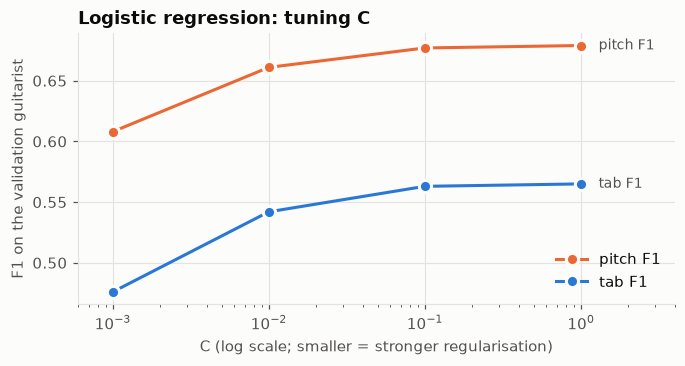

best C by tab F1: 1.0


In [28]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for metric, color, label in [("pitch_f1", PAIR[1], "pitch F1"), ("tab_f1", PAIR[0], "tab F1")]:
    ax.plot(c_table["C"], c_table[metric], marker="o", markersize=8, color=color, label=label,
            markeredgecolor=SURFACE, markeredgewidth=2)
    ax.text(c_table["C"].iloc[-1] * 1.3, c_table[metric].iloc[-1], label, color=INK_2, va="center", fontsize=9)
ax.set_xscale("log")
ax.set_xlim(0.0006, 4)
ax.set_xlabel("C (log scale; smaller = stronger regularisation)")
ax.set_ylabel("F1 on the validation guitarist")
ax.set_title("Logistic regression: tuning C")
ax.legend(loc="lower right")
plt.show()

best_C = float(c_table.loc[c_table["tab_f1"].idxmax(), "C"])
print("best C by tab F1:", best_C)

F1 grows quickly up to C = 0.1 and then flattens (0.563 → 0.565 at C = 1). C = 1 is the edge of the
range we tried, but the curve is already flat there and a weaker regularisation only makes fitting
slower (94 s vs 62 s), so we stop at C = 1.

#### Class weights
Rare frets have few examples (EDA §3.4). `class_weight="balanced"` gives every class the same total
weight, so rare frets count more during training. We compare it with no weighting at the best C.

In [29]:
weighted_model, info = fit_logreg(X_delta, C=best_C, class_weight="balanced")
proba_weighted = weighted_model.predict_proba(X_delta[val_mask])
weight_rows = [r for r in c_rows if r["C"] == best_C] + [
    evaluate(f"logreg C={best_C}, balanced class weights", decide(proba_weighted), C=best_C, **info)]
show(weight_rows)

,model,tab_f1,tab_precision,tab_recall,pitch_f1,string_choice,accuracy,pitch_precision,pitch_recall,C,fit_seconds,converged
0,logreg C=1.0,0.565,0.666,0.491,0.679,0.831,0.747,0.800,0.590,1.0,93,True
1,"logreg C=1.0, balanced class weights",0.534,0.439,0.681,0.625,0.854,0.621,0.514,0.797,1.0,63,True


Balanced weights push the model to predict notes much more often (the silent class gets a tiny
weight): recall jumps from 0.49 to 0.68 but precision falls from 0.67 to 0.44, and F1 drops.
Interestingly, the string choice *improves* (0.854 vs 0.831): rare positions high up the neck are
learned better. The decision threshold below is a more direct way to control the
precision/recall trade-off, so we keep **no class weights**.

#### Tuning the decision threshold
Course lesson 4.2 showed that 0.5 is not necessarily the best threshold. Here a string is predicted
as playing when P(playing) = 1 − P(silent) is above a threshold, and its fret is the most likely of the
20 playing classes (`guitar.decide`). Lowering the threshold trades precision for recall:

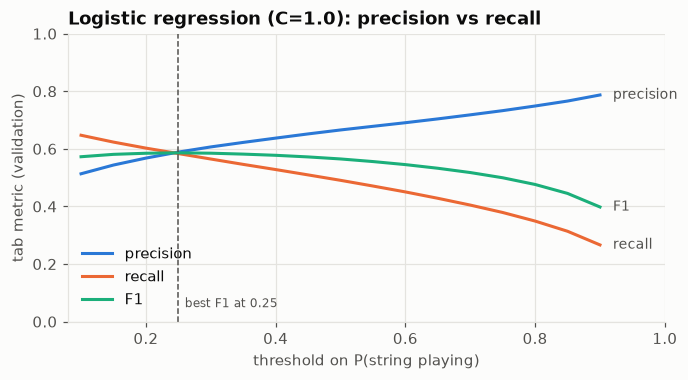

,model,tab_f1,tab_precision,tab_recall,pitch_f1,string_choice,accuracy,pitch_precision,pitch_recall,C,fit_seconds,converged,threshold,model_mb
0,"logreg C=1.0, balanced class weights",0.534,0.439,0.681,0.625,0.854,0.621,0.514,0.797,1.0,63,True,NaN,NaN
1,"logreg C=1.0, threshold 0.25",0.586,0.589,0.584,0.702,0.835,0.737,0.705,0.699,1.0,93,NaN,0.25,0.2


In [30]:
best_model, best_proba = c_models[best_C]
thresholds = np.round(np.arange(0.1, 0.91, 0.05), 2)
thr_table = pd.DataFrame([{"threshold": t, **tab_metrics(y_val, decide(best_proba, t))} for t in thresholds])

fig, ax = plt.subplots(figsize=(7, 3.4))
for metric, color, label in [("tab_precision", STRING_COLORS[0], "precision"),
                             ("tab_recall", STRING_COLORS[1], "recall"),
                             ("tab_f1", STRING_COLORS[2], "F1")]:
    ax.plot(thr_table["threshold"], thr_table[metric], color=color, label=label)
    ax.text(0.92, thr_table[metric].iloc[-1], label, color=INK_2, va="center", fontsize=9)
best_t = float(thr_table.loc[thr_table["tab_f1"].idxmax(), "threshold"])
ax.axvline(best_t, color=INK_2, linewidth=1, linestyle="--")
ax.text(best_t + 0.01, 0.05, f"best F1 at {best_t}", color=INK_2, fontsize=8)
ax.set_xlim(0.08, 1.0)
ax.set_ylim(0, 1)
ax.set_xlabel("threshold on P(string playing)")
ax.set_ylabel("tab metric (validation)")
ax.set_title(f"Logistic regression (C={best_C}): precision vs recall")
ax.legend(loc="lower left")
plt.show()

import pickle
best_fit_seconds = next(r["fit_seconds"] for r in c_rows if r["C"] == best_C)  # same model, new threshold
evaluate(f"logreg C={best_C}, threshold {best_t}", decide(best_proba, best_t), C=best_C, threshold=best_t,
         fit_seconds=best_fit_seconds, model_mb=round(len(pickle.dumps(best_model)) / 1e6, 1))
show(results[-2:])

A lower threshold than 0.5 gives the best F1: the model is a bit too shy to predict notes, so we let
it predict a note when it is less sure. Note that the threshold is tuned on the validation guitarist,
so the final check will be on the test guitarist.

#### Is the string playing at all? ROC AUC
Ignoring the fret, how well does P(playing) separate playing from silent frames? This is a binary
problem per string, so we can use ROC AUC (course lessons 4.5–4.6):

In [31]:
auc = {STRINGS[s]: roc_auc_score(y_val[:, s] > 0, 1 - best_proba[:, s, 0]) for s in range(6)}
pd.Series(auc, name="ROC AUC (string playing vs silent)").round(3).to_frame().T

,E,A,D,G,B,e
ROC AUC (string playing vs silent),0.891,0.904,0.874,0.841,0.852,0.85


Detecting *whether* a string plays is fairly easy (AUC well above 0.5 for every string). The hard
part is the fret and the string choice.

#### Results per string

In [32]:
pred_best = decide(best_proba, best_t)
per_string = pd.DataFrame(
    [tab_metrics(y_val[:, [s]], pred_best[:, [s]]) for s in range(6)], index=STRINGS
)[["tab_precision", "tab_recall", "tab_f1"]].round(3)
per_string["notes in validation"] = (y_val > 0).sum(axis=0)
per_string

,tab_precision,tab_recall,tab_f1,notes in validation
E,0.796,0.623,0.699,20469
A,0.702,0.660,0.680,29632
D,0.572,0.636,0.602,36502
G,0.506,0.616,0.556,36203
B,0.506,0.552,0.528,34884
e,0.646,0.408,0.500,28724


* The low strings are the easiest (E: F1 0.70, A: 0.68): their pitch range overlaps with fewer
  other strings.
* G and B have the lowest precision: their pitches are shared with the strings around them (EDA §3.5).
* The high e string has the lowest recall (0.41): the model misses many of its notes.

#### Interpreting the model
Course lesson 3.11 reads the logistic regression weights. Each string's model has one weight per
(class, feature). Here are the weights of the **G string** model on the 168 spectrogram features
(features are standardised, so the weights are comparable). The dots mark where the fundamental of
each fret is.

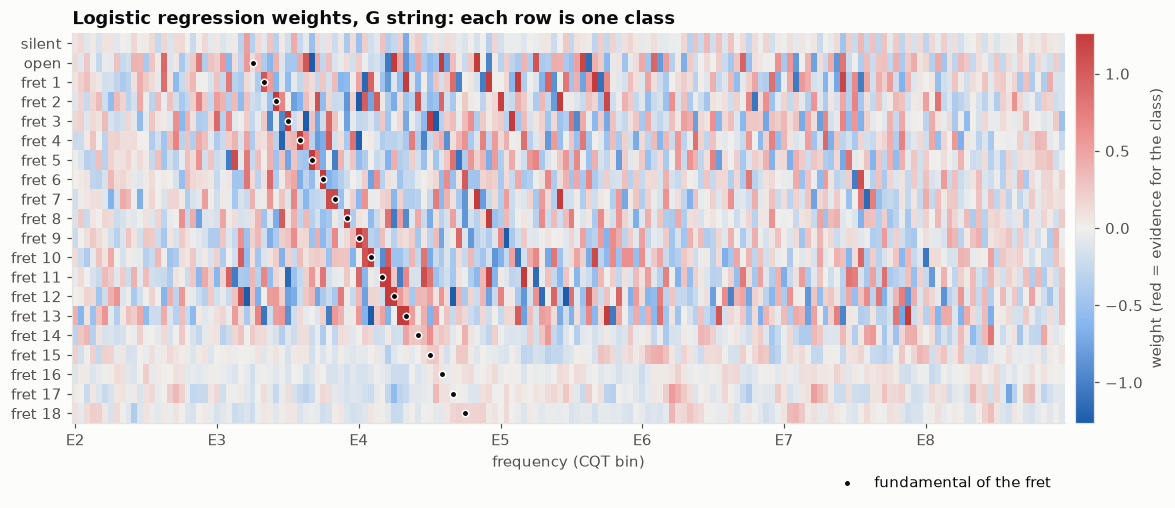

In [33]:
s = 3  # G string
lr = best_model.estimators_[s][-1]
classes = best_model.classes_[s]
coef = lr.coef_[:, :F.N_BINS]
labels = ["silent" if c == 0 else "open" if c == 1 else f"fret {c - 1}" for c in classes]

fig, ax = plt.subplots(figsize=(12, 4.6))
lim = np.percentile(np.abs(coef), 99)
im = ax.imshow(coef, cmap=BLUE_RED, vmin=-lim, vmax=lim, aspect="auto")
fund = [(F.OPEN_STRING_MIDI[s] + c - 1 - 40) * 2 for c in classes if c > 0]
ax.scatter(fund, np.flatnonzero(classes > 0), s=18, facecolor=INK, edgecolor="white", linewidth=1,
           label="fundamental of the fret")
ax.set_yticks(range(len(classes)), labels)
ax.set_xticks(OCTAVE_TICKS, OCTAVE_LABELS)
ax.grid(False)
ax.set_xlabel("frequency (CQT bin)")
ax.set_title("Logistic regression weights, G string: each row is one class")
ax.legend(loc="upper right", bbox_to_anchor=(1, -0.1), frameon=False)
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="weight (red = evidence for the class)")
plt.show()

Each fret class has its strongest positive (red) weight at its own fundamental frequency, giving a
diagonal line: the model learned "fret *k* on the G string = energy at that pitch". There are
negative (blue) weights at neighbouring pitches, so it also learned to tell adjacent frets apart.
The rare high frets (15–18) have weak, washed-out weights: there were too few examples to learn them.

### 5.4 Baseline summary

In [34]:
show(pd.DataFrame(results).drop_duplicates("model").to_dict("records"))

,model,tab_f1,tab_precision,tab_recall,pitch_f1,string_choice,accuracy,pitch_precision,pitch_recall,fit_seconds,converged,C,threshold,model_mb
0,dummy: always silent,0.000,0.000,0.000,0.000,0.000,0.606,0.000,0.000,NaN,NaN,NaN,NaN,NaN
1,"logreg C=0.1, spectrogram only (168)",0.548,0.669,0.464,0.663,0.826,0.739,0.810,0.562,36.0,True,NaN,NaN,NaN
2,"logreg C=0.1, spectrogram + deltas (336)",0.563,0.671,0.485,0.677,0.831,0.747,0.808,0.583,59.0,True,NaN,NaN,NaN
3,logreg C=0.001,0.476,0.613,0.389,0.608,0.783,0.708,0.783,0.496,47.0,True,0.001,NaN,NaN
4,logreg C=0.01,0.542,0.665,0.458,0.661,0.821,0.738,0.810,0.558,43.0,True,0.010,NaN,NaN
5,logreg C=0.1,0.563,0.671,0.485,0.677,0.831,0.747,0.808,0.583,61.0,True,0.100,NaN,NaN
6,logreg C=1.0,0.565,0.666,0.491,0.679,0.831,0.747,0.800,0.590,93.0,True,1.000,NaN,NaN
7,"logreg C=1.0, balanced class weights",0.534,0.439,0.681,0.625,0.854,0.621,0.514,0.797,63.0,True,1.000,NaN,NaN
8,"logreg C=1.0, threshold 0.25",0.586,0.589,0.584,0.702,0.835,0.737,0.705,0.699,93.0,NaN,1.000,0.25,0.2


* The dummy model shows why accuracy is useless here: 61% accuracy, zero notes found.
* Logistic regression already gives a usable baseline: **tab F1 0.586** on the validation guitarist
  (C = 1, delta features, threshold 0.25). Its string choice (0.835) is far above the 63.5% of the
  "most common string" rule, so it does use the timbre, not just the pitch.
* What helped: the delta features (+0.015), tuning C (+0.09 over C = 0.001) and a lower decision
  threshold (+0.02). Class weights did not.

Next: tree-based models (decision tree, random forest, XGBoost) can combine features non-linearly
(e.g. "energy at the fundamental AND weak 3rd harmonic"), which might help the string choice.

## 6. Tree-based models

Course module 6: decision tree → random forest → gradient boosting (XGBoost). Same setup as for
logistic regression: 336 features (spectrogram + deltas), the same 100,000 training frames, all
frames of the validation guitarist, one model per string via `StringwiseClassifier`.

To compare model families fairly, every model gets its own decision threshold, tuned on the
validation guitarist exactly as in §5.3, and we report the tab metrics at that threshold.

In [35]:
import pickle
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

X_train_d, X_val_d = X_delta[train_idx], X_delta[val_mask]
THRESHOLDS = np.round(np.r_[0.02, np.arange(0.05, 0.91, 0.05)], 2)

def best_threshold(proba, y_true=None):
    y_true = y_val if y_true is None else y_true
    return max(THRESHOLDS, key=lambda t: tab_metrics(y_true, decide(proba, t))["tab_f1"])

def score(proba, **extra):
    """Tab metrics on the validation guitarist at the best threshold for this model."""
    t = best_threshold(proba)
    return {**tab_metrics(y_val, decide(proba, t)), "threshold": t, **extra}

def fit_model(estimator, X_fit=None, y_fit=None):
    model = StringwiseClassifier(estimator)
    start = time.time()
    model.fit(X_train_d if X_fit is None else X_fit, y_train if y_fit is None else y_fit)
    return model, round(time.time() - start)

def model_mb(model):
    return round(len(pickle.dumps(model)) / 1e6, 1)

def tuning_table(rows, *keys):
    cols = list(keys) + ["tab_f1", "tab_precision", "tab_recall", "string_choice", "threshold", "fit_seconds"]
    return pd.DataFrame(rows)[cols].round(3)

### 6.1 Decision tree
A single tree learns if-then rules such as "bin 62 > −30 dB and bin 86 < −45 dB → G string, fret 3".
We tune `max_depth` first and then `min_samples_leaf` (course lesson 6.5).

In [36]:
dt_rows = []
for depth in [4, 6, 8, 10, 12, 15, 20]:
    model, secs = fit_model(DecisionTreeClassifier(max_depth=depth, random_state=1))
    dt_rows.append(score(model.predict_proba(X_val_d), max_depth=depth, fit_seconds=secs))
dt_depth = tuning_table(dt_rows, "max_depth")
dt_depth

,max_depth,tab_f1,tab_precision,tab_recall,string_choice,threshold,fit_seconds
0,4,0.287,0.334,0.252,0.636,0.40,10
1,6,0.342,0.342,0.343,0.691,0.25,15
2,8,0.377,0.391,0.363,0.714,0.30,23
3,10,0.398,0.441,0.362,0.725,0.30,25
4,12,0.404,0.437,0.375,0.735,0.25,30
5,15,0.401,0.432,0.374,0.740,0.20,36
6,20,0.393,0.457,0.344,0.743,0.30,50


In [37]:
top_depths = dt_depth.sort_values("tab_f1", ascending=False)["max_depth"].iloc[:2].tolist()
dt_leaf_rows = []
for depth in top_depths:
    for leaf in [1, 10, 50, 200]:
        model, secs = fit_model(DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1))
        dt_leaf_rows.append(score(model.predict_proba(X_val_d), max_depth=depth, min_samples_leaf=leaf,
                                  fit_seconds=secs))
dt_leaf = tuning_table(dt_leaf_rows, "max_depth", "min_samples_leaf")
dt_leaf.pivot(index="min_samples_leaf", columns="max_depth", values="tab_f1")

max_depth,12,15
min_samples_leaf,,
1,0.404,0.401
10,0.408,0.411
50,0.408,0.414
200,0.405,0.412


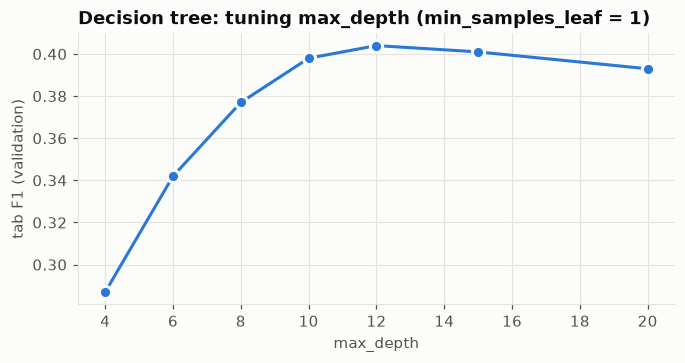

best decision tree: {'max_depth': 15, 'min_samples_leaf': 50}  tab F1: 0.414


In [38]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(dt_depth["max_depth"], dt_depth["tab_f1"], marker="o", markersize=8, color=STRING_COLORS[0],
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_xlabel("max_depth")
ax.set_ylabel("tab F1 (validation)")
ax.set_title("Decision tree: tuning max_depth (min_samples_leaf = 1)")
plt.show()

dt_best = dt_leaf.loc[dt_leaf["tab_f1"].idxmax()]
DT_PARAMS = dict(max_depth=int(dt_best["max_depth"]), min_samples_leaf=int(dt_best["min_samples_leaf"]))
print("best decision tree:", DT_PARAMS, " tab F1:", dt_best["tab_f1"])

In [39]:
dt_model, secs = fit_model(DecisionTreeClassifier(**DT_PARAMS, random_state=1))
dt_proba = dt_model.predict_proba(X_val_d)
dt_t = best_threshold(dt_proba)
evaluate(f"decision tree {DT_PARAMS}", decide(dt_proba, dt_t), threshold=dt_t, fit_seconds=secs,
         model_mb=model_mb(dt_model))
show(results[-1:])

,model,tab_f1,tab_precision,tab_recall,pitch_f1,string_choice,accuracy,pitch_precision,pitch_recall,threshold,fit_seconds,model_mb
0,"decision tree {'max_depth': 15, 'min_samples_l...",0.414,0.411,0.418,0.564,0.735,0.639,0.559,0.569,0.25,36,1.5


The tree improves quickly up to depth 10–12 and then stops improving: deeper trees only memorise the
training frames. Larger leaves help a little (0.404 → 0.414 with `min_samples_leaf=50` at depth 15).
Still, the best tree (tab F1 0.414) is far behind logistic regression (0.586). A tree tests one
frequency bin at a time, while a note shows up as a pattern across many bins (fundamental plus
harmonics), which a linear model weighs all at once.

### 6.2 Random forest
Many trees, each trained on a bootstrap sample of the frames and choosing among a random subset of
features at every split; their probabilities are averaged (course lesson 6.6).

First the number of trees. Instead of retraining for every value, we train one forest of 100 trees
and average the predictions of its first *n* trees, which gives the same curve.

In [40]:
def forest_proba_curve(model, X_eval, checkpoints):
    """Probabilities of the first n trees of each string's forest, for every n in checkpoints."""
    out = {n: np.zeros((len(X_eval), 6, F.N_CLASSES), dtype=np.float32) for n in checkpoints}
    for s, (forest, classes) in enumerate(zip(model.estimators_, model.classes_)):
        running = np.zeros((len(X_eval), len(classes)), dtype=np.float32)
        for i, tree in enumerate(forest.estimators_, start=1):
            running += tree.predict_proba(X_eval)
            if i in out:
                out[i][:, s, classes] = running / i
    return out

rf_model, secs = fit_model(RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=2, random_state=1))
rf_curve = forest_proba_curve(rf_model, X_val_d, [10, 25, 50, 75, 100])
rf_trees = tuning_table([score(p, n_estimators=n, fit_seconds=secs) for n, p in rf_curve.items()], "n_estimators")
del rf_model, rf_curve
rf_trees

,n_estimators,tab_f1,tab_precision,tab_recall,string_choice,threshold,fit_seconds
0,10,0.471,0.465,0.478,0.763,0.35,141
1,25,0.501,0.493,0.509,0.775,0.35,141
2,50,0.512,0.479,0.550,0.788,0.30,141
3,75,0.517,0.483,0.555,0.791,0.30,141
4,100,0.519,0.485,0.557,0.792,0.30,141


Then `max_depth` and `min_samples_leaf`, with 50 trees to keep training time reasonable:

In [41]:
rf_rows = []
for depth in [10, 20, None]:
    model, secs = fit_model(RandomForestClassifier(n_estimators=50, max_depth=depth, min_samples_leaf=5,
                                                   n_jobs=2, random_state=1))
    rf_rows.append(score(model.predict_proba(X_val_d), max_depth=str(depth), min_samples_leaf=5,
                         fit_seconds=secs, model_mb=model_mb(model)))
    del model
rf_depth = tuning_table(rf_rows, "max_depth", "min_samples_leaf").assign(model_mb=[r["model_mb"] for r in rf_rows])
rf_depth

,max_depth,min_samples_leaf,tab_f1,tab_precision,tab_recall,string_choice,threshold,fit_seconds,model_mb
0,10,5,0.471,0.450,0.495,0.758,0.3,27,73.6
1,20,5,0.512,0.483,0.544,0.788,0.3,48,410.0
2,None,5,0.512,0.479,0.550,0.788,0.3,67,496.6


In [42]:
best_rf_depth = rf_rows[int(np.argmax([r["tab_f1"] for r in rf_rows]))]["max_depth"]
best_rf_depth = None if best_rf_depth == "None" else int(best_rf_depth)

rf_leaf_rows = [r for r in rf_rows if r["max_depth"] == str(best_rf_depth)]
for leaf in [2, 15, 50]:
    model, secs = fit_model(RandomForestClassifier(n_estimators=50, max_depth=best_rf_depth, min_samples_leaf=leaf,
                                                   n_jobs=2, random_state=1))
    rf_leaf_rows.append(score(model.predict_proba(X_val_d), max_depth=str(best_rf_depth), min_samples_leaf=leaf,
                              fit_seconds=secs, model_mb=model_mb(model)))
    del model
rf_leaf = (tuning_table(rf_leaf_rows, "max_depth", "min_samples_leaf")
           .assign(model_mb=[r["model_mb"] for r in rf_leaf_rows]).sort_values("min_samples_leaf"))
rf_leaf

,max_depth,min_samples_leaf,tab_f1,tab_precision,tab_recall,string_choice,threshold,fit_seconds,model_mb
1,None,2,0.509,0.475,0.549,0.789,0.3,76,792.6
0,None,5,0.512,0.479,0.550,0.788,0.3,67,496.6
2,None,15,0.506,0.473,0.543,0.784,0.3,54,238.5
3,None,50,0.487,0.454,0.525,0.770,0.3,41,92.4


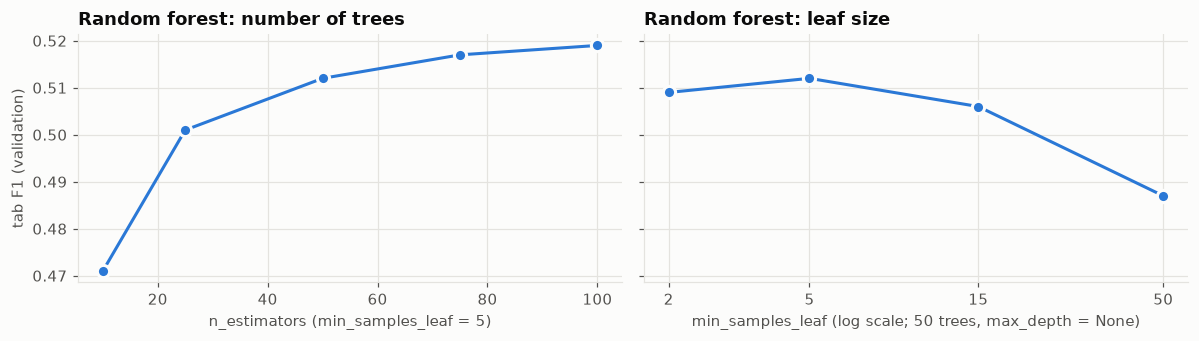

best random forest: {'n_estimators': 50, 'max_depth': None, 'min_samples_leaf': 5}  tab F1: 0.512


In [43]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
ax = axes[0]
ax.plot(rf_trees["n_estimators"], rf_trees["tab_f1"], marker="o", markersize=8, color=STRING_COLORS[0],
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_xlabel("n_estimators (min_samples_leaf = 5)")
ax.set_ylabel("tab F1 (validation)")
ax.set_title("Random forest: number of trees")
ax = axes[1]
ax.plot(rf_leaf["min_samples_leaf"], rf_leaf["tab_f1"], marker="o", markersize=8, color=STRING_COLORS[0],
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_xscale("log")
ax.set_xticks(rf_leaf["min_samples_leaf"], [str(int(v)) for v in rf_leaf["min_samples_leaf"]])
ax.minorticks_off()
ax.set_xlabel(f"min_samples_leaf (log scale; 50 trees, max_depth = {best_rf_depth})")
ax.set_title("Random forest: leaf size")
plt.tight_layout()
plt.show()

rf_best = rf_leaf.loc[rf_leaf["tab_f1"].idxmax()]
RF_PARAMS = dict(n_estimators=50, max_depth=best_rf_depth, min_samples_leaf=int(rf_best["min_samples_leaf"]))
print("best random forest:", RF_PARAMS, " tab F1:", rf_best["tab_f1"])

In [44]:
rf_model, secs = fit_model(RandomForestClassifier(**RF_PARAMS, n_jobs=2, random_state=1))
rf_proba = rf_model.predict_proba(X_val_d)
rf_t = best_threshold(rf_proba)
evaluate(f"random forest {RF_PARAMS}", decide(rf_proba, rf_t), threshold=rf_t, fit_seconds=secs,
         model_mb=model_mb(rf_model))
del rf_model
show(results[-1:])

,model,tab_f1,tab_precision,tab_recall,pitch_f1,string_choice,accuracy,pitch_precision,pitch_recall,threshold,fit_seconds,model_mb
0,"random forest {'n_estimators': 50, 'max_depth'...",0.512,0.479,0.55,0.65,0.788,0.674,0.608,0.698,0.3,66,496.6


Averaging many trees helps a lot: 0.414 for one tree, 0.512 for 50 trees. More trees still help but
with diminishing returns (+0.007 from 50 to 100 trees). Unlimited depth with small leaves (5) works
best, but the price is size: the 50-tree forest is about 500 MB, which is impractical to ship in a
Docker image. At tab F1 0.512 it is also still below logistic regression.

### 6.3 XGBoost
Gradient boosting trains trees one after another, each correcting the errors of the previous ones
(course lesson 6.7). With 21 classes, XGBoost grows 21 trees per round for each string, so it is the
slowest model here. Two settings keep it practical on a CPU and are not tuned:
`tree_method="hist"` with `max_bin=64` (features are bucketed into 64 bins: about twice as fast, and
tab F1 within 0.003 of the default 256 bins in a quick test).

As in course lesson 6.8 we tune `eta` (learning rate), then `max_depth`, then `min_child_weight`,
looking at the validation score after every few boosting rounds. One model with N rounds gives the
whole curve: `predict_proba(..., iteration_range=(0, k))` uses only the first k rounds.

In [45]:
ROUNDS = 200
CHECKPOINTS = [25, 50, 100, 150, 200]
XGB_FIXED = dict(tree_method="hist", max_bin=64, n_jobs=2, random_state=1)

xgb_models = {}  # (eta, max_depth, min_child_weight) -> trained model, reused below instead of refitting

def xgb_proba(model, X_eval, k):
    """Probabilities using only the first k boosting rounds."""
    proba = np.zeros((len(X_eval), 6, F.N_CLASSES), dtype=np.float32)
    for s, (est, classes) in enumerate(zip(model.estimators_, model.classes_)):
        proba[:, s, classes] = est.predict_proba(X_eval, iteration_range=(0, k))
    return proba

def xgb_curve(params, rounds=ROUNDS, checkpoints=CHECKPOINTS):
    model, secs = fit_model(XGBClassifier(n_estimators=rounds, **params, **XGB_FIXED))
    xgb_models[(params["learning_rate"], params["max_depth"], params["min_child_weight"])] = model
    rows = [score(xgb_proba(model, X_val_d, k), rounds=k, fit_seconds=secs, **params) for k in checkpoints]
    return pd.DataFrame(rows)

def plot_curves(ax, curves, param, title):
    for i, (value, curve) in enumerate(curves.items()):
        ax.plot(curve["rounds"], curve["tab_f1"], marker="o", markersize=6, color=STRING_COLORS[i],
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=f"{param} = {value}")
    ax.set_xlabel("boosting rounds")
    ax.set_title(title)
    ax.legend(loc="lower right")

In [46]:
eta_curves = {eta: xgb_curve(dict(learning_rate=eta, max_depth=6, min_child_weight=1)) for eta in [0.3, 0.1]}
pd.concat(eta_curves.values())[["learning_rate", "rounds", "tab_f1", "threshold", "fit_seconds"]].round(3)

,learning_rate,rounds,tab_f1,threshold,fit_seconds
0,0.3,25,0.545,0.20,325
1,0.3,50,0.565,0.15,325
2,0.3,100,0.582,0.10,325
3,0.3,150,0.593,0.10,325
4,0.3,200,0.599,0.05,325
0,0.1,25,0.535,0.25,321
1,0.1,50,0.559,0.25,321
2,0.1,100,0.581,0.20,321
3,0.1,150,0.592,0.20,321
4,0.1,200,0.598,0.20,321


In [47]:
def best_of(curves):
    """(parameter value, rounds, tab F1) of the best point over all curves."""
    value, curve = max(curves.items(), key=lambda kv: kv[1]["tab_f1"].max())
    row = curve.loc[curve["tab_f1"].idxmax()]
    return value, int(row["rounds"]), row["tab_f1"]

best_eta, _, _ = best_of(eta_curves)
print("best eta:", best_eta)

best eta: 0.3


In [48]:
depth_curves = {6: eta_curves[best_eta]}
for depth in [4, 8]:
    depth_curves[depth] = xgb_curve(dict(learning_rate=best_eta, max_depth=depth, min_child_weight=1))
depth_curves = dict(sorted(depth_curves.items()))
best_depth, _, _ = best_of(depth_curves)
print("best max_depth:", best_depth)

best max_depth: 6


In [49]:
mcw_curves = {1: depth_curves[best_depth]}
for mcw in [10, 30]:
    mcw_curves[mcw] = xgb_curve(dict(learning_rate=best_eta, max_depth=best_depth, min_child_weight=mcw))
best_mcw, best_rounds, best_xgb_f1 = best_of(mcw_curves)
print("best min_child_weight:", best_mcw, " rounds:", best_rounds, " tab F1:", round(best_xgb_f1, 3))

best min_child_weight: 30  rounds: 200  tab F1: 0.61


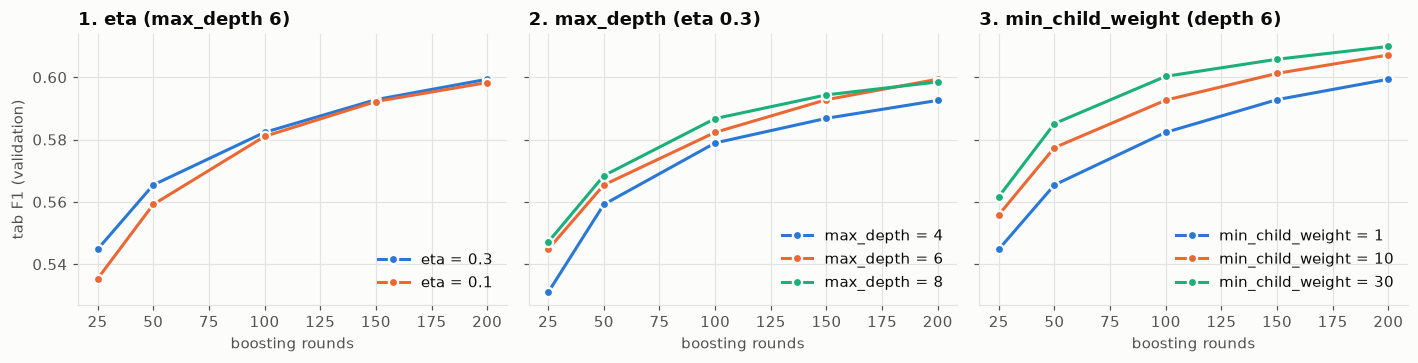

best XGBoost: {'n_estimators': 200, 'learning_rate': 0.3, 'max_depth': 6, 'min_child_weight': 30}


In [50]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
plot_curves(axes[0], eta_curves, "eta", "1. eta (max_depth 6)")
plot_curves(axes[1], depth_curves, "max_depth", f"2. max_depth (eta {best_eta})")
plot_curves(axes[2], mcw_curves, "min_child_weight", f"3. min_child_weight (depth {best_depth})")
axes[0].set_ylabel("tab F1 (validation)")
plt.tight_layout()
plt.show()

XGB_PARAMS = dict(n_estimators=best_rounds, learning_rate=best_eta, max_depth=best_depth,
                  min_child_weight=best_mcw)
print("best XGBoost:", XGB_PARAMS)

In [51]:
# The tuning run with the best settings already contains this model: use its first best_rounds rounds.
xgb_model = xgb_models[(best_eta, best_depth, best_mcw)]
best_xgb_proba = xgb_proba(xgb_model, X_val_d, best_rounds)
xgb_t = best_threshold(best_xgb_proba)
evaluate(f"XGBoost {XGB_PARAMS}", decide(best_xgb_proba, xgb_t), threshold=xgb_t,
         fit_seconds=int(mcw_curves[best_mcw]["fit_seconds"].iloc[0]),  # measured for all ROUNDS rounds
         model_mb=model_mb(xgb_model))                                    # size with all ROUNDS rounds
show(results[-1:])

,model,tab_f1,tab_precision,tab_recall,pitch_f1,string_choice,accuracy,pitch_precision,pitch_recall,threshold,fit_seconds,model_mb
0,"XGBoost {'n_estimators': 200, 'learning_rate':...",0.61,0.602,0.618,0.73,0.835,0.752,0.721,0.74,0.15,267,30.1


What the curves show:
- **eta:** 0.3 learns faster, but after 200 rounds both learning rates end up at the same score
  (0.599 vs 0.598). We keep 0.3.
- **max_depth:** depth 4 is too shallow; depths 6 and 8 end at the same score, so we keep the
  simpler depth 6.
- **min_child_weight:** larger values (each leaf needs more evidence) help: 0.599 → 0.607 → 0.610 for
  1, 10 and 30. Like C for logistic regression, the best value is at the edge of the range we tried,
  but the gains are shrinking.

All curves are still rising slowly at 200 rounds, so more rounds would add a little. We stop at 200
because each fit already takes about 5–6 minutes on 100,000 frames.

The tuned XGBoost (tab F1 **0.610**, threshold 0.15) is the first model to beat logistic regression
(0.586) on the validation guitarist. It finds more of the right pitches (pitch F1 0.730 vs 0.702)
and chooses the string equally well (0.835 for both). The saved model is 30 MB.

### 6.4 Feature importance from XGBoost
Which features does the boosted model rely on? `feature_importances_` (share of the total gain) per
string, split into the spectrogram bins and the delta bins (from the tuning model with all rounds):

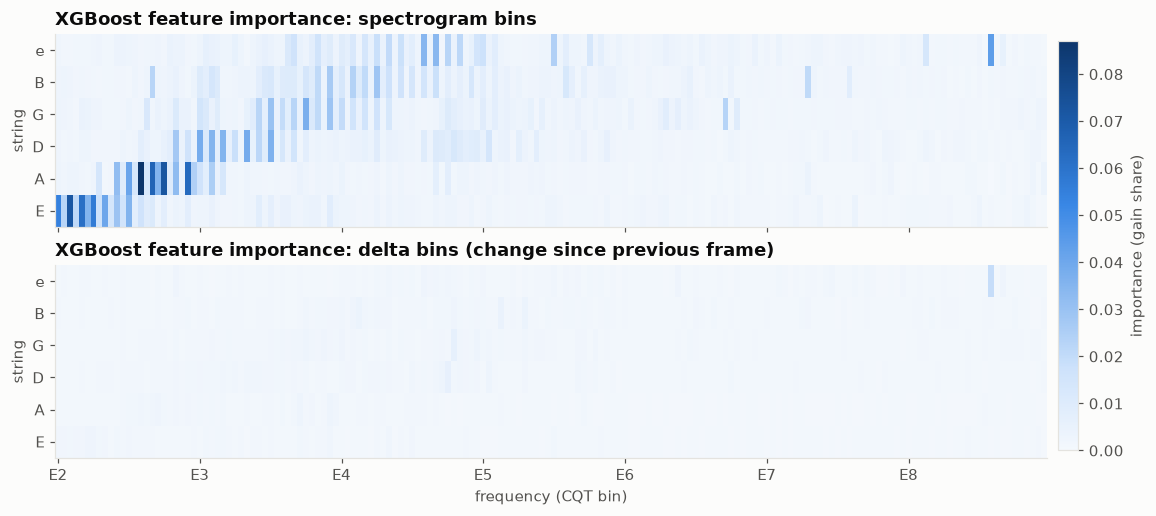

share of total importance on delta features: 18.5%


In [52]:
importance = np.stack([est.feature_importances_ for est in xgb_model.estimators_])  # (6, 336)
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for ax, part, title in [(axes[0], slice(0, F.N_BINS), "spectrogram bins"),
                        (axes[1], slice(F.N_BINS, 2 * F.N_BINS), "delta bins (change since previous frame)")]:
    im = ax.imshow(importance[::-1, part], cmap=BLUES, aspect="auto", vmin=0, vmax=importance.max())
    ax.set_yticks(range(6), STRINGS[::-1])
    ax.set_ylabel("string")
    ax.grid(False)
    ax.set_title(f"XGBoost feature importance: {title}")
axes[1].set_xticks(OCTAVE_TICKS, OCTAVE_LABELS)
axes[1].set_xlabel("frequency (CQT bin)")
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label="importance (gain share)")
plt.show()
print(f"share of total importance on delta features: {importance[:, F.N_BINS:].sum() / importance.sum():.1%}")

Each string's model looks mostly at the frequencies that string can play: the low E and A strings at
the bottom of the range (E2–E3), and the important region moves up the frequency axis from string to
string, much like the mutual information in EDA §4.1. The delta features get 18.5% of the total
importance: useful but secondary, which matches the small gain from adding them in §5.3. One isolated
high bin (near the top of the range) is also used by the e string model; we have not investigated why.

## 7. Selecting the best model

The best configuration of each model family, on the validation guitarist:

In [53]:
summary = pd.DataFrame(results).drop_duplicates("model")
family_best = []
for family, prefix in [("dummy", "dummy"), ("logistic regression", "logreg"), ("decision tree", "decision tree"),
                       ("random forest", "random forest"), ("XGBoost", "XGBoost")]:
    rows = summary[summary["model"].str.startswith(prefix)]
    if rows["threshold"].notna().any():  # compare every family at its own tuned threshold
        rows = rows[rows["threshold"].notna()]
    family_best.append(rows.loc[rows["tab_f1"].idxmax()].to_dict() | {"family": family})
comparison = pd.DataFrame(family_best).set_index("family")[
    ["model", "tab_f1", "tab_precision", "tab_recall", "pitch_f1", "string_choice", "threshold",
     "fit_seconds", "model_mb"]].round(3)
comparison

,model,tab_f1,tab_precision,tab_recall,pitch_f1,string_choice,threshold,fit_seconds,model_mb
family,,,,,,,,,
dummy,dummy: always silent,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN
logistic regression,"logreg C=1.0, threshold 0.25",0.586,0.589,0.584,0.702,0.835,0.25,93.0,0.2
decision tree,"decision tree {'max_depth': 15, 'min_samples_l...",0.414,0.411,0.418,0.564,0.735,0.25,36.0,1.5
random forest,"random forest {'n_estimators': 50, 'max_depth'...",0.512,0.479,0.550,0.650,0.788,0.30,66.0,496.6
XGBoost,"XGBoost {'n_estimators': 200, 'learning_rate':...",0.610,0.602,0.618,0.730,0.835,0.15,267.0,30.1


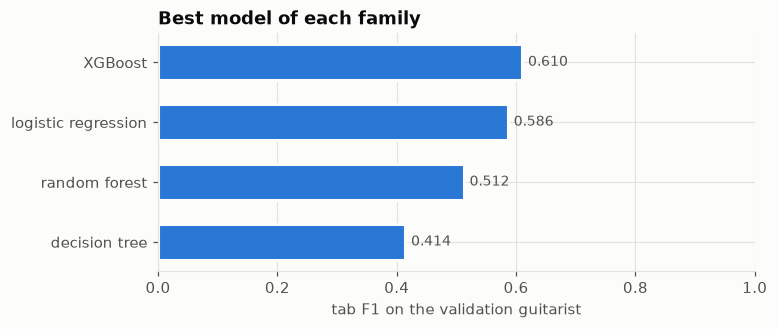

In [54]:
cmp = comparison.drop(index="dummy").sort_values("tab_f1")
fig, ax = plt.subplots(figsize=(7, 2.8))
bars = ax.barh(cmp.index, cmp["tab_f1"], color=STRING_COLORS[0], height=0.6, **BAR)
for bar, v in zip(bars, cmp["tab_f1"]):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2, f"{v:.3f}", va="center",
            color=INK_2, fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel("tab F1 on the validation guitarist")
ax.set_title("Best model of each family")
plt.show()

XGBoost and logistic regression are the two serious candidates. Single trees and random forests are
clearly worse here, and the forest is also by far the largest model.

### 7.1 Is the difference real? Cross-validation over guitarists
The comparison above uses a single validation guitarist, who also turned out to be the most chordal
player (EDA §3.7). To check that the ranking holds for other players, we run **leave-one-guitarist-out
cross-validation** (course lesson 4.7, with guitarists as folds) on the 5 non-test guitarists for the
two best families: each fold trains on 100,000 frames of 4 guitarists and is scored on all frames of
the 5th. The thresholds are the ones tuned above (not re-tuned per fold).

In [55]:
LOGREG_PARAMS = dict(C=best_C)   # tuned in §5.3
LOGREG_T = best_t                 # threshold tuned in §5.3
XGB_T = float(comparison.loc["XGBoost", "threshold"])

def make_logreg():
    return make_pipeline(StandardScaler(), LogisticRegression(**LOGREG_PARAMS, max_iter=1000))

def make_xgb():
    return XGBClassifier(**XGB_PARAMS, **XGB_FIXED)

cv_rows = []
for fold_player in sorted(set(range(6)) - {test_player}):
    fold_players = tracks["player"].to_numpy()[track]
    fit_pool = np.flatnonzero((frame_split != "test") & (fold_players != fold_player))
    fit_idx = np.sort(np.random.default_rng(1).choice(fit_pool, size=N_TRAIN, replace=False))
    eval_mask = fold_players == fold_player
    for name, make, t in [("logistic regression", make_logreg, LOGREG_T), ("XGBoost", make_xgb, XGB_T)]:
        model, secs = fit_model(make(), X_delta[fit_idx], y[fit_idx])
        pred = decide(model.predict_proba(X_delta[eval_mask]), t)
        cv_rows.append({"model": name, "held-out guitarist": fold_player,
                        **tab_metrics(y[eval_mask], pred), "fit_seconds": secs})
cv = pd.DataFrame(cv_rows)
cv.pivot(index="held-out guitarist", columns="model", values="tab_f1").round(3)

model,XGBoost,logistic regression
held-out guitarist,,
0,0.610,0.586
1,0.656,0.619
2,0.683,0.667
3,0.665,0.631
5,0.667,0.619


In [56]:
cv_summary = cv.groupby("model")[["tab_f1", "pitch_f1", "string_choice"]].agg(["mean", "std"]).round(3)
wins = (cv.pivot(index="held-out guitarist", columns="model", values="tab_f1")
        .pipe(lambda t: (t["XGBoost"] > t["logistic regression"]).sum()))
print(f"XGBoost beats logistic regression on {wins} of {cv['held-out guitarist'].nunique()} guitarists")
cv_summary

XGBoost beats logistic regression on 5 of 5 guitarists


tab_f1        pitch_f1        string_choice       
                      mean    std     mean    std          mean    std
model                                                                 
XGBoost              0.656  0.028    0.742  0.018         0.884  0.030
logistic regression  0.624  0.029    0.701  0.020         0.891  0.034

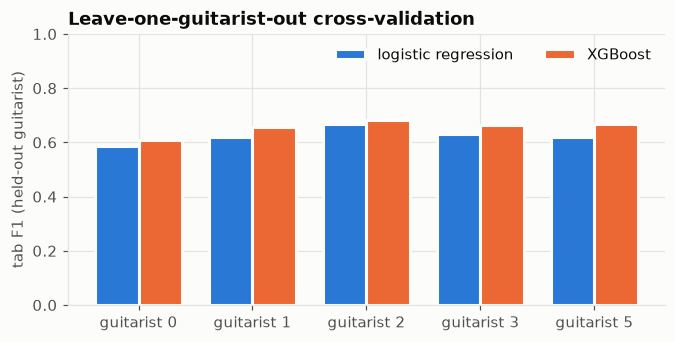

In [57]:
cv_pivot = cv.pivot(index="held-out guitarist", columns="model", values="tab_f1")
fig, ax = plt.subplots(figsize=(7, 3.2))
xs = np.arange(len(cv_pivot))
for i, (name, color) in enumerate(zip(["logistic regression", "XGBoost"], PAIR)):
    ax.bar(xs + (i - 0.5) * 0.38, cv_pivot[name], width=0.38, color=color, label=name, **BAR)
ax.set_xticks(xs, [f"guitarist {p}" for p in cv_pivot.index])
ax.set_ylim(0, 1)
ax.set_ylabel("tab F1 (held-out guitarist)")
ax.set_title("Leave-one-guitarist-out cross-validation")
ax.legend(loc="upper right", ncol=2)
plt.show()

XGBoost is better for **every** held-out guitarist, by 0.016 to 0.048 tab F1, so the ranking from the
single validation guitarist holds. The fold for guitarist 0 reproduces the validation scores above
(same training frames), and guitarist 0 is the hardest player for both models, as expected for the
most chordal player. Differences *between* guitarists (0.61–0.68 for XGBoost) are larger than the
difference between the models.

Interestingly, logistic regression is slightly better at choosing the string (0.891 vs 0.884 on
average). XGBoost's advantage comes from detecting which pitches are sounding (pitch F1 0.742 vs 0.701).

### 7.2 The final model
We pick the family with the best **mean** tab F1 across the guitarist folds. Following course lesson
1.5, the final model is retrained with the selected settings on **train + validation guitarists**
(more data, 5 players instead of 4) and evaluated **once** on the test guitarist, who was not used
for anything so far. The decision threshold is the one tuned on validation.

The final training sample is 200,000 frames (twice the tuning sample) to keep training time on a CPU
reasonable; `production/train.py` does exactly the same thing.

In [58]:
cv_means = cv.groupby("model")["tab_f1"].mean()
FINAL_FAMILY = cv_means.idxmax()
make_final, FINAL_T = {"logistic regression": (make_logreg, LOGREG_T), "XGBoost": (make_xgb, XGB_T)}[FINAL_FAMILY]
print(f"selected: {FINAL_FAMILY} (mean CV tab F1 {cv_means[FINAL_FAMILY]:.3f}), threshold {FINAL_T}")

N_FINAL = 2 * N_TRAIN
full_train_idx = np.sort(np.random.default_rng(1).choice(np.flatnonzero(frame_split != "test"),
                                                          size=N_FINAL, replace=False))
final_model, secs = fit_model(make_final(), X_delta[full_train_idx], y[full_train_idx])
print(f"trained on {N_FINAL} frames in {secs} s")

test_mask = frame_split == "test"
y_test = y[test_mask]
test_pred = decide(final_model.predict_proba(X_delta[test_mask]), FINAL_T)
test_scores = tab_metrics(y_test, test_pred)

val_scores = comparison.loc[FINAL_FAMILY, ["tab_f1", "tab_precision", "tab_recall", "pitch_f1", "string_choice"]]
pd.DataFrame({
    "validation (guitarist %d, tuning model)" % val_player: val_scores,
    "test (guitarist %d, final model)" % test_player: pd.Series(test_scores)[val_scores.index],
    "cross-validation mean": cv.groupby("model")[val_scores.index.tolist()].mean().loc[FINAL_FAMILY],
}).round(3)

selected: XGBoost (mean CV tab F1 0.656), threshold 0.15


trained on 200000 frames in 552 s


,"validation (guitarist 0, tuning model)","test (guitarist 4, final model)",cross-validation mean
tab_f1,0.610,0.696,0.656
tab_precision,0.602,0.631,0.606
tab_recall,0.618,0.775,0.719
pitch_f1,0.730,0.750,0.742
string_choice,0.835,0.928,0.884


In [59]:
per_string_test = pd.DataFrame(
    [tab_metrics(y_test[:, [s]], test_pred[:, [s]]) for s in range(6)], index=STRINGS
)[["tab_precision", "tab_recall", "tab_f1"]].round(3)
per_string_test["playing frames in test"] = (y_test > 0).sum(axis=0)
per_string_test

,tab_precision,tab_recall,tab_f1,playing frames in test
E,0.828,0.710,0.764,16187
A,0.688,0.801,0.740,16382
D,0.608,0.790,0.687,26073
G,0.620,0.794,0.696,31212
B,0.587,0.777,0.669,28447
e,0.574,0.745,0.648,12394


**Result on the test guitarist: tab F1 0.696** (pitch F1 0.750, and the string is right for 92.8% of
correctly detected pitches).

This is higher than the cross-validation mean (0.656) and than every single fold. There are two
likely reasons, which we cannot separate without using the test set again:
1. The final model is trained on twice as many frames, from 5 guitarists instead of 4.
2. Guitarist 4 seems to be an easier player for this model: the string choice (0.928) is much higher
   than for any validation fold.

So 0.66–0.70 is a fair expectation for a new player from this dataset. On recordings that are less
like GuitarSet (other guitars, microphones or rooms) it will be lower.

Recall (0.775) is clearly higher than precision (0.631). The threshold of 0.15 was tuned on the most
chordal guitarist, and it is a little too eager for other players. The next step (`production/guitar.py`) turns
frames into notes and drops very short notes, which removes many of these false positives.

Per string, the low strings are the easiest (E 0.764) and the high strings the hardest (e 0.648), roughly
the same order as for logistic regression in §5.3 (only D and G swap places).

**Selected model:** XGBoost (200 rounds, eta 0.3, max_depth 6, min_child_weight 30, `hist` with 64
bins), one model per string, decision threshold 0.15, trained on 200,000 frames of guitarists 0, 1,
2, 3 and 5. `production/train.py` reproduces this model.